# Semi-supervised forest training and two example predictions

This notebook delegates training to `train_vision_semi.py` instead of duplicating its training loop. That keeps the model, losses, schedules, checkpoint selection, and logging exactly the same as the script. After training, it loads `checkpoints/best.pt` and plots occupancy predictions for two forest images.

Run the notebook from the repository root, where `train_vision_semi.py`, `model.py`, `augmentations.py`, and the project modules are available. Edit the paths and training arguments in the next cell to match your run.

In [5]:
from pathlib import Path
import sys
import subprocess

# Run this notebook from the pose_from_cylinders repository root.
REPO_DIR = Path.cwd()
TRAIN_SCRIPT = REPO_DIR / "train_vision_semi.py"

# Match the short experiment configuration. Other values are the script defaults.
TRAIN_ARGS = {
    "--data-dir": ".",
    "--forest-dir": "forestdataset/skrylle",
    "--forest-stride": 1,
    "--epochs": 100,
    "--batch-size": 16,
    "--val-interval": 10,
    "--num-workers": 8,
    "--img-size": 224,
    "--consistency-warmup-epochs": 10,
    "--consistency-ramp-epochs": 50,
    "--lambda-consistency": 1.0,
    "--lambda-occ-prior": 0.5,
    "--occ-prior-final-factor": 0.1,
    "--lambda-entropy": 0.05,
    "--topk-fraction": 0.072,
    "--lambda-topk-feedback": 0.05,
    "--output-dir": "runs/vision_semi_notebook",
}

# Optional: set this to an occupancy-pretrained checkpoint to continue in geometry
# stage. If set, the script requires --stage geometry.
#INIT_CHECKPOINT = "runs/vision_geometry_good/checkpoints/best_vision.pt" 
INIT_CHECKPOINT = "arrhenius_runs/slurm_vision_geometry_224_2_5658352/checkpoints/best_vision.pt"
if INIT_CHECKPOINT is not None:
    TRAIN_ARGS["--stage"] = "geometry"
    TRAIN_ARGS["--init-checkpoint"] = str(INIT_CHECKPOINT)

assert TRAIN_SCRIPT.exists(), f"Could not find {TRAIN_SCRIPT}. Set REPO_DIR to the repository root."
print("Repository:", REPO_DIR)
print("Training script:", TRAIN_SCRIPT)
print("Output:", REPO_DIR / TRAIN_ARGS["--output-dir"])

Repository: /home/johanna/Doktorand/pose_from_cylinders
Training script: /home/johanna/Doktorand/pose_from_cylinders/train_vision_semi.py
Output: /home/johanna/Doktorand/pose_from_cylinders/runs/vision_semi_notebook


## Train

The next cell runs the script with the arguments above. It can take as long as a normal script run. The selected checkpoint will be saved under the output directory's `checkpoints/best.pt`.

In [6]:
cmd = [sys.executable, str(TRAIN_SCRIPT)]
for name, value in TRAIN_ARGS.items():
    cmd.extend([name, str(value)])

print("Running:", " ".join(cmd), flush=True)
subprocess.run(cmd, cwd=REPO_DIR, check=True)

Running: /home/johanna/Doktorand/pose_from_cylinders/venv/bin/python /home/johanna/Doktorand/pose_from_cylinders/train_vision_semi.py --data-dir . --forest-dir forestdataset/skrylle --forest-stride 1 --epochs 100 --batch-size 16 --val-interval 10 --num-workers 8 --img-size 224 --consistency-warmup-epochs 10 --consistency-ramp-epochs 50 --lambda-consistency 1.0 --lambda-occ-prior 0.5 --occ-prior-final-factor 0.1 --lambda-entropy 0.05 --topk-fraction 0.072 --lambda-topk-feedback 0.05 --output-dir runs/vision_semi_notebook --stage geometry --init-checkpoint arrhenius_runs/slurm_vision_geometry_224_2_5658352/checkpoints/best_vision.pt
Device: cuda | supervised=482 | validation=484 | forest=1948
Loaded checkpoint arrhenius_runs/slurm_vision_geometry_224_2_5658352/checkpoints/best_vision.pt epoch 40
Epoch 1: total=5.4146 supervised=3.5271 cons=0.3024 (w=0.000) (occ=0.0060, geom=0.2964) occ_prior=0.2710*0.500 entropy=0.3070*0.0000 topk=1.1823*0.0000 topk_mutual=3.49/10 topk_overlap=0.349 gt_o

CompletedProcess(args=['/home/johanna/Doktorand/pose_from_cylinders/venv/bin/python', '/home/johanna/Doktorand/pose_from_cylinders/train_vision_semi.py', '--data-dir', '.', '--forest-dir', 'forestdataset/skrylle', '--forest-stride', '1', '--epochs', '100', '--batch-size', '16', '--val-interval', '10', '--num-workers', '8', '--img-size', '224', '--consistency-warmup-epochs', '10', '--consistency-ramp-epochs', '50', '--lambda-consistency', '1.0', '--lambda-occ-prior', '0.5', '--occ-prior-final-factor', '0.1', '--lambda-entropy', '0.05', '--topk-fraction', '0.072', '--lambda-topk-feedback', '0.05', '--output-dir', 'runs/vision_semi_notebook', '--stage', 'geometry', '--init-checkpoint', 'arrhenius_runs/slurm_vision_geometry_224_2_5658352/checkpoints/best_vision.pt'], returncode=0)

## Plot two forest examples

For each original image, the notebook runs the same pair model with that image supplied to both inputs, matching the two-view training setup. The right-hand plot shows occupancy probability by angular bin; the dashed line is the forest consistency threshold from the script arguments.

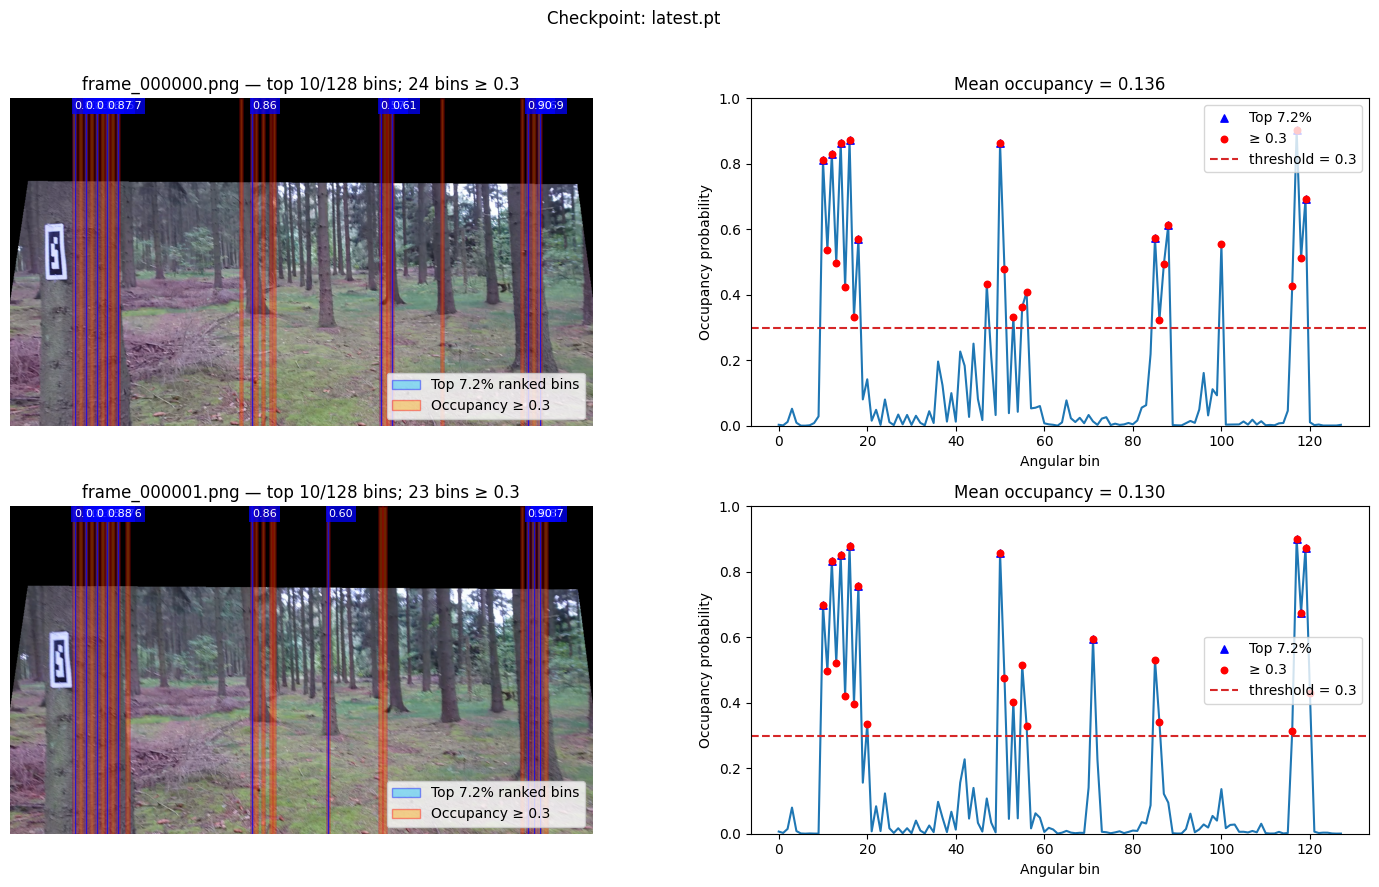

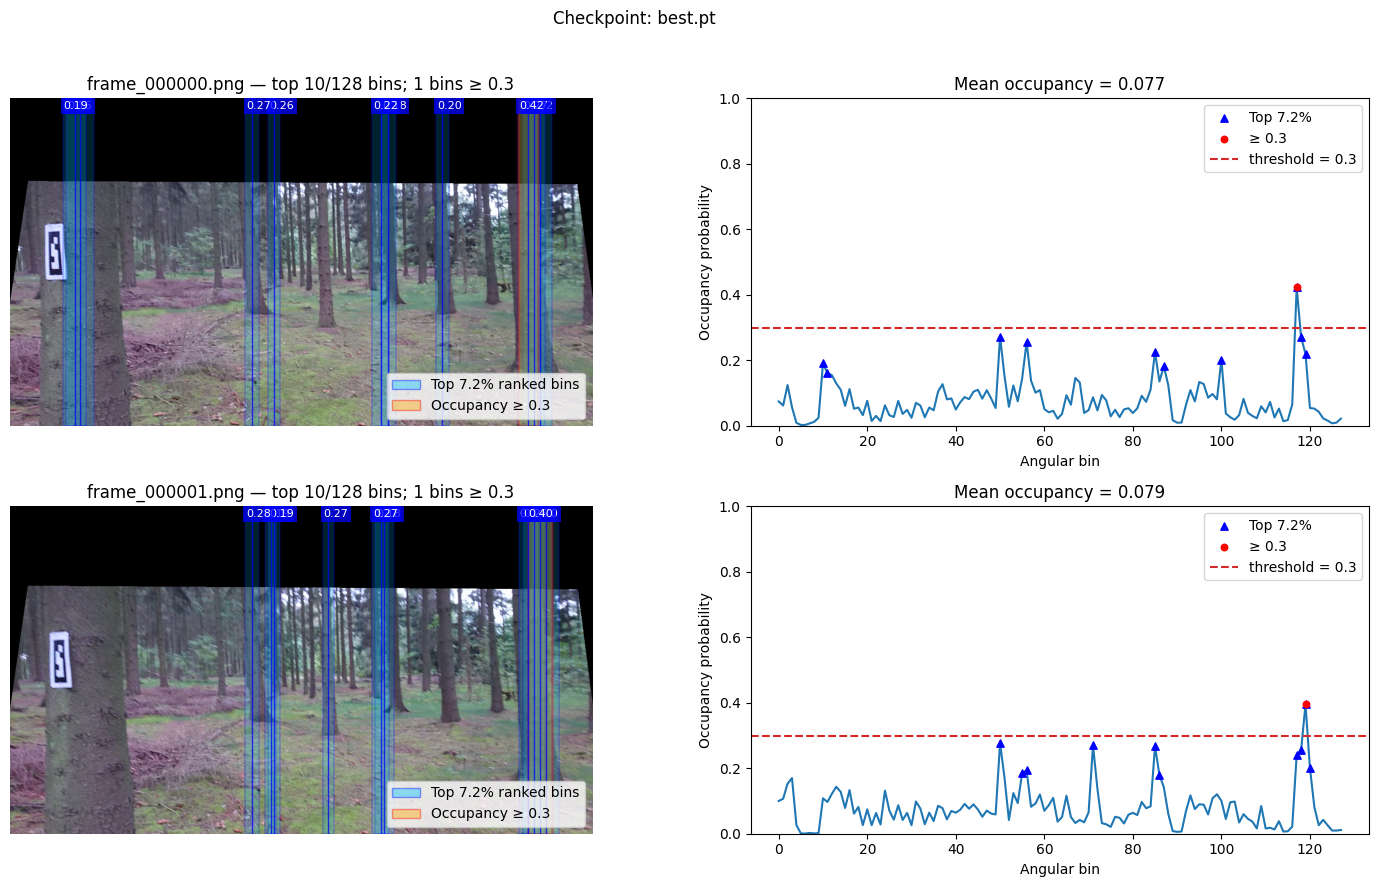

In [10]:
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import Patch, Rectangle
from PIL import Image

from augmentations import build_eval_transform
from model import PairImageCylinderModel

output_dir = REPO_DIR / TRAIN_ARGS["--output-dir"]
forest_dir = Path(TRAIN_ARGS["--forest-dir"])
if not forest_dir.is_absolute():
    forest_dir = REPO_DIR / forest_dir

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
top_fraction = 0.072
fov_degrees = 90.0


def load_model(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    args = checkpoint["args"]
    model = PairImageCylinderModel(
        img_size=args["img_size"],
        patch_size=tuple(args["patch_size"]),
        in_chans=3,
        embed_dim=args["embed_dim"],
        depth=args["depth"],
        num_heads=args["num_heads"],
        num_bins=args["num_bins"],
        dropout=args["dropout"],
    ).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model, args


def get_example_images(poses_file):
    with open(poses_file, "r", encoding="utf-8") as f:
        pairs = json.load(f)

    image_names = []
    seen = set()
    for pair in pairs:
        for key in ("from_image", "to_image"):
            name = pair[key]
            if name not in seen:
                image_names.append(name)
                seen.add(name)
            if len(image_names) == 2:
                break
        if len(image_names) == 2:
            break

    if len(image_names) < 2:
        raise RuntimeError("Forest dataset needs at least two distinct images.")
    return image_names


def add_bin_span(ax, bin_idx, occupancy, width_degrees, bin_angles,
                 image_size, fov_degrees, color, edgecolor, alpha,
                 linewidth, label_text=None, draw_centerline=True):
    image_width, image_height = image_size
    focal_px = image_width / (2.0 * np.tan(np.deg2rad(fov_degrees / 2.0)))
    center_px = image_width / 2.0
    center_angle = bin_angles[bin_idx]
    half_width = max(float(width_degrees[bin_idx]), 0.0) / 2.0
    left_angle, right_angle = np.clip(
        [center_angle - half_width, center_angle + half_width],
        -fov_degrees / 2.0,
        fov_degrees / 2.0,
    )
    left_px = np.clip(center_px + focal_px * np.tan(np.deg2rad(left_angle)), 0, image_width)
    right_px = np.clip(center_px + focal_px * np.tan(np.deg2rad(right_angle)), 0, image_width)

    ax.add_patch(Rectangle(
        (left_px, 0),
        max(right_px - left_px, 1),
        image_height,
        facecolor=color,
        edgecolor=edgecolor,
        linewidth=linewidth,
        alpha=alpha,
    ))

    if draw_centerline:
        center_px_bin = center_px + focal_px * np.tan(np.deg2rad(center_angle))
        ax.axvline(center_px_bin, color=edgecolor, linewidth=1, alpha=0.75)
    if label_text is not None:
        ax.text(
            np.clip(left_px + 2, 2, max(image_width - 45, 2)),
            5,
            label_text,
            color="white",
            fontsize=8,
            va="top",
            bbox={"facecolor": edgecolor, "alpha": 0.75, "edgecolor": "none", "pad": 2},
        )


def plot_checkpoint(checkpoint_name):
    checkpoint_path = output_dir / "checkpoints" / checkpoint_name
    model, saved_args = load_model(checkpoint_path)
    poses_file = forest_dir / f"relative_poses_stride_{saved_args['forest_stride']}.json"
    image_names = get_example_images(poses_file)
    transform = build_eval_transform(saved_args["img_size"])
    threshold = float(saved_args.get("forest_occ", 0.3))

    fig, axes = plt.subplots(
        2, 2,
        figsize=(15, 9),
        gridspec_kw={"width_ratios": [1.3, 1.0]},
    )
    fig.suptitle(f"Checkpoint: {checkpoint_path.name}")

    for row, name in enumerate(image_names):
        image_path = forest_dir / "images" / name
        with Image.open(image_path) as im:
            image = im.convert("RGB")

        image_tensor = transform(image).unsqueeze(0).to(device)
        with torch.inference_mode():
            outputs = model(
                image_tensor,
                image_tensor,
                return_corr=False,
                compute_pose=False,
            )
            prediction = outputs[0][0].float().cpu().numpy()

        occupancy = prediction[:, 0]
        width_degrees = prediction[:, 3]
        num_bins = len(occupancy)
        top_k = max(1, math.ceil(top_fraction * num_bins))
        top_bins = np.argsort(occupancy)[-top_k:]
        threshold_bins = np.flatnonzero(occupancy >= threshold)
        bin_angles = np.linspace(-fov_degrees / 2.0, fov_degrees / 2.0, num_bins)

        image_ax = axes[row, 0]
        image_ax.imshow(image)
        for bin_idx in top_bins:
            add_bin_span(
                image_ax, bin_idx, occupancy, width_degrees, bin_angles, image.size,
                fov_degrees, "deepskyblue", "blue", 0.18, 1.3,
                label_text=f"{occupancy[bin_idx]:.2f}",
            )
        for bin_idx in threshold_bins:
            add_bin_span(
                image_ax, bin_idx, occupancy, width_degrees, bin_angles, image.size,
                fov_degrees, "orange", "red", 0.28, 1.8, draw_centerline=False,
            )

        image_ax.set_title(
            f"{name} — top {top_k}/{num_bins} bins; "
            f"{len(threshold_bins)} bins ≥ {threshold:g}"
        )
        image_ax.axis("off")
        image_ax.legend(
            handles=[
                Patch(facecolor="deepskyblue", edgecolor="blue", alpha=0.4,
                      label=f"Top {top_fraction:.1%} ranked bins"),
                Patch(facecolor="orange", edgecolor="red", alpha=0.4,
                      label=f"Occupancy ≥ {threshold:g}"),
            ],
            loc="lower right",
        )

        curve_ax = axes[row, 1]
        bins = np.arange(num_bins)
        curve_ax.plot(bins, occupancy, linewidth=1.5)
        curve_ax.scatter(
            top_bins, occupancy[top_bins], color="blue", marker="^", s=28,
            label=f"Top {top_fraction:.1%}", zorder=3,
        )
        curve_ax.scatter(
            threshold_bins, occupancy[threshold_bins], color="red", s=22,
            label=f"≥ {threshold:g}", zorder=4,
        )
        curve_ax.axhline(
            threshold, color="tab:red", linestyle="--",
            label=f"threshold = {threshold:g}",
        )
        curve_ax.set_ylim(0, 1)
        curve_ax.set_xlabel("Angular bin")
        curve_ax.set_ylabel("Occupancy probability")
        curve_ax.set_title(f"Mean occupancy = {occupancy.mean():.3f}")
        curve_ax.legend()

    plt.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()


for checkpoint_name in ("latest.pt", "best.pt"):
    plot_checkpoint(checkpoint_name)
